Importamos los paquetes necesarios

In [2]:
#!/usr/bin/python3
import os
import sys
from collections import deque

import cv2
import joblib
import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import torch
from deepface import DeepFace
from joblib import Parallel, delayed
from mtcnn import MTCNN
from PIL import Image
from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tensorflow.keras import layers, models

I0000 00:00:1795782985.077747   20529 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795782985.335966   20529 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795782987.056296   20529 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


26-11-27 12:36:30 - Directory /home/jero/.deepface has been created
26-11-27 12:36:30 - Directory /home/jero/.deepface/weights has been created


In [2]:
os.environ["KERAS_BACKEND"] = "torch"

try:
    tf.config.set_visible_devices([], "GPU")
except Exception:
    pass

# Selección de dispositivo: GPU si existe, si no CPU
if torch.cuda.is_available():
    DEVICE = "gpu:0"
    print("Usando GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("No se detectó GPU, usando CPU")

Usando GPU: NVIDIA GeForce RTX 5070 Laptop GPU


Entrenamiento 1

Detección de características

In [5]:
EXTENSIONES = (".png", ".jpg", ".jpeg")
IMG_SIZE = 112


# Recibir una cara en escala de grises y devolver el vector HOG.
def hog_cara(gris):
    gris = cv2.resize(gris, (IMG_SIZE, IMG_SIZE))
    return hog(
        gris,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
    )


def _procesar(ruta):
    img = cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)
    return None if img is None else hog_cara(img)

Carga de datos

In [ ]:
def cargar(carpeta, clases=None):
    if clases is None:
        clases = sorted(
            d for d in os.listdir(carpeta) if os.path.isdir(os.path.join(carpeta, d))
        )
    rutas, etiquetas = [], []
    for i, c in enumerate(clases):
        d = os.path.join(carpeta, c)
        for f in os.listdir(d):
            if f.lower().endswith(EXTENSIONES):
                rutas.append(os.path.join(d, f))
                etiquetas.append(i)
    print(f"Extrayendo HOG de {len(rutas)} imágenes en {carpeta}...")
    feats = Parallel(n_jobs=-1)(delayed(_procesar)(r) for r in rutas)
    ok = [i for i, f in enumerate(feats) if f is not None]
    X = np.array([feats[i] for i in ok])
    y = np.array([etiquetas[i] for i in ok])
    return X, y, clases


def localizar_raiz(root):
    if not os.path.isdir(root):
        sys.exit(
            f"No existe la carpeta '{root}'. Ejecuta el script desde el "
            f"directorio que la contiene o pasa la ruta completa."
        )
    for _ in range(3):
        subs = [d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))]
        if "train" in subs or len(subs) != 1:
            break
        root = os.path.join(root, subs[0])
    print("Usando carpeta:", root)
    print("Contiene:", sorted(os.listdir(root))[:15])
    return root


def cargar_todo(root):
    root = localizar_raiz(root)
    train_dir = os.path.join(root, "train")
    if os.path.isdir(train_dir):
        X_tr, y_tr, clases = cargar(train_dir)
        test_dir = next(
            (
                os.path.join(root, n)
                for n in ("test", "validation")
                if os.path.isdir(os.path.join(root, n))
            ),
            None,
        )
        if test_dir:
            X_te, y_te, _ = cargar(test_dir, clases)
        else:
            X_tr, X_te, y_tr, y_te = train_test_split(
                X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=42
            )
    else:
        X, y, clases = cargar(root)
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, stratify=y, random_state=42
        )
    return X_tr, X_te, y_tr, y_te, clases


Entrenamiento de la parte 1

Usando carpeta: dataset
Contiene: ['test', 'train', 'validation']
Extrayendo HOG de 66379 imágenes en dataset/train...
Extrayendo HOG de 3573 imágenes en dataset/test...
Clases: ['angry', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'suprise']
Train: (66379, 6084) Test: (3573, 6084)
Imágenes por clase (train): {'angry': np.int64(8000), 'contempt': np.int64(8000), 'disgust': np.int64(8000), 'fear': np.int64(8000), 'happy': np.int64(8000), 'neutral': np.int64(10379), 'sad': np.int64(8000), 'suprise': np.int64(8000)}
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Mejores parámetros: {'svc__C': 10, 'svc__gamma': 'scale'}
              precision    recall  f1-score   support

       angry       0.62      0.57      0.59       322
    contempt       0.73      0.27      0.39        30
     disgust       0.60      0.43      0.50        21
        fear       0.59      0.33      0.42        98
       happy       0.79      0.79      0.79       929
     neutral       0.68 

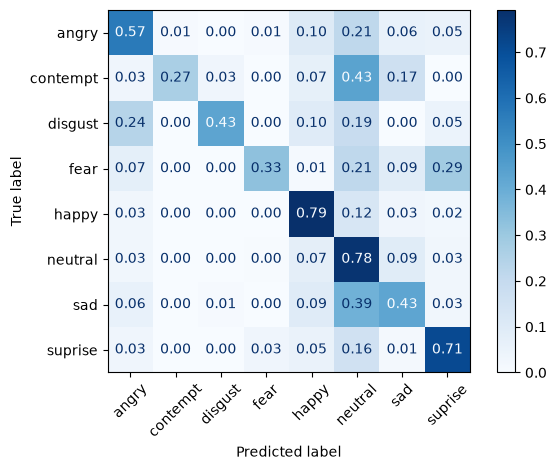

Modelo guardado en emociones_clasico.joblib


In [ ]:
N_PCA = 150


def main(root="dataset"):
    os.makedirs("train1", exist_ok=True)
    X_tr, X_te, y_tr, y_te, clases = cargar_todo(root)
    print("Clases:", clases)
    print("Train:", X_tr.shape, "Test:", X_te.shape)
    print("Imágenes por clase (train):", dict(zip(clases, np.bincount(y_tr))))

    pipe = make_pipeline(
        StandardScaler(),
        PCA(n_components=N_PCA, svd_solver="randomized", random_state=0),
        SVC(kernel="rbf", class_weight="balanced"),
    )

    # Búsqueda de hiperparámetros sobre una submuestra (para que sea rápido)
    n = min(5000, len(X_tr))
    idx = np.random.RandomState(0).choice(len(X_tr), n, replace=False)
    grid = GridSearchCV(
        pipe,
        {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.001, 0.0001]},
        cv=3,
        scoring="f1_macro",
        n_jobs=1,
        verbose=1,
    )
    grid.fit(X_tr[idx], y_tr[idx])
    print("Mejores parámetros:", grid.best_params_)

    # Entrenamiento final con todos los datos de train
    pipe.set_params(**grid.best_params_)
    pipe.fit(X_tr, y_tr)

    # Evaluación
    pred = pipe.predict(X_te)
    print(classification_report(y_te, pred, target_names=clases, zero_division=0))
    print("F1 macro:", f1_score(y_te, pred, average="macro"))

    ConfusionMatrixDisplay.from_predictions(
        y_te,
        pred,
        display_labels=clases,
        xticks_rotation=45,
        normalize="true",
        cmap="Blues",
        values_format=".2f",
    )
    plt.tight_layout()
    plt.savefig("./train1/matriz_confusion_clasico.png", dpi=150)
    plt.show()

    joblib.dump({"modelo": pipe, "clases": clases}, "./train1/emociones_clasico.joblib")
    print("Modelo guardado en train1/emociones_clasico.joblib")

main("dataset")

Entrenamiento 2

In [ ]:
os.makedirs("train2", exist_ok=True)
train = tf.keras.utils.image_dataset_from_directory(
    "./dataset/train",
    image_size=(112, 112),
    color_mode="grayscale",
    batch_size=64,
    label_mode="categorical",
)

val = tf.keras.utils.image_dataset_from_directory(
    "./dataset/validation",
    image_size=(112, 112),
    color_mode="grayscale",
    batch_size=64,
    label_mode="categorical",
    shuffle=False,
)

with keras.device(DEVICE):
    model = models.Sequential(
        [
            layers.Input(shape=(112, 112, 1)),
            layers.Rescaling(1 / 255),
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            layers.Conv2D(32, 3, activation="relu"),
            layers.MaxPooling2D(),
            layers.Conv2D(64, 3, activation="relu"),
            layers.MaxPooling2D(),
            layers.Conv2D(128, 3, activation="relu"),
            layers.Flatten(),
            layers.Dropout(0.4),
            layers.Dense(128, activation="relu"),
            layers.Dense(8, activation="softmax"),
        ]
    )

    model.compile("adam", "categorical_crossentropy", metrics=["accuracy"])
    model.fit(
        train,
        validation_data=val,
        epochs=30,
        callbacks=[
            keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
        ],
    )
    model.save("./train2/emociones.keras")

    y_pred = np.argmax(model.predict(val), axis=1)

# Evaluación
clases = val.class_names

y_true = np.concatenate([np.argmax(y, axis=1) for _, y in val])

print(classification_report(y_true, y_pred, target_names=clases, zero_division=0))
print("F1 macro:", f1_score(y_true, y_pred, average="macro"))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=clases,
    normalize="true",
    xticks_rotation=45,
    cmap="Blues",
    values_format=".2f",
)
plt.tight_layout()
plt.savefig("./train2/matriz_confusion_cnn.png", dpi=150)
plt.show()

Entrenamiento con RESNET50V2

Found 66379 files belonging to 8 classes.
Found 8341 files belonging to 8 classes.
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/4


c:\Users\nedeg\anaconda3\envs\VC_P5\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1038/1038 ━━━━━━━━━━━━━━━━━━━━ 255s 242ms/step - accuracy: 0.4091 - loss: 1.7555 - val_accuracy: 0.4972 - val_loss: 1.4463
Epoch 2/4
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 247s 238ms/step - accuracy: 0.4673 - loss: 1.5040 - val_accuracy: 0.4864 - val_loss: 1.4769
Epoch 3/4
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 244s 235ms/step - accuracy: 0.4772 - loss: 1.4900 - val_accuracy: 0.4984 - val_loss: 1.4512
Epoch 4/4
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 239s 230ms/step - accuracy: 0.4763 - loss: 1.4853 - val_accuracy: 0.5052 - val_loss: 1.4161
Epoch 1/8
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 374s 356ms/step - accuracy: 0.7042 - loss: 0.8264 - val_accuracy: 0.6708 - val_loss: 1.0279
Epoch 2/8
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 370s 357ms/step - accuracy: 0.8323 - loss: 0.4688 - val_accuracy: 0.6822 - val_loss: 1.2419
Epoch 3/8
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 379s 365ms/step - accuracy: 0.8719 - loss: 0.3516 - val_accuracy: 0.6677 - val_loss: 1.3409
Epoch 4/8
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 386s 372ms/step - accuracy: 0.8970 - l

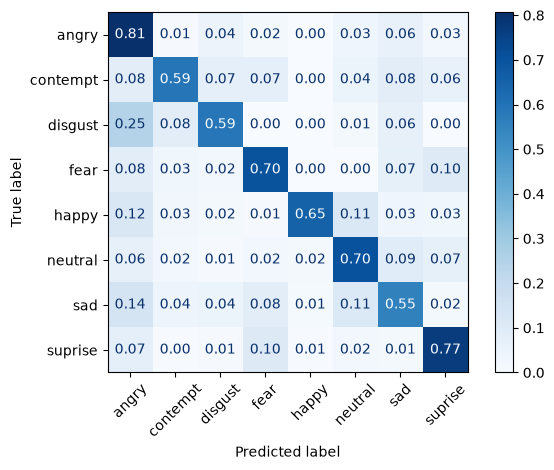

In [ ]:
os.makedirs("train2", exist_ok=True)

BATCH = 64
PESOS = "imagenet"
FASE1_EPOCHS = 4
FASE2_EPOCHS = 8
CAPAS_AJUSTE = 50

train = tf.keras.utils.image_dataset_from_directory(
    "./dataset/train",
    image_size=(112, 112),
    color_mode="grayscale",
    batch_size=BATCH,
    label_mode="categorical",
)

val = tf.keras.utils.image_dataset_from_directory(
    "./dataset/validation",
    image_size=(112, 112),
    color_mode="grayscale",
    batch_size=BATCH,
    label_mode="categorical",
    shuffle=False,
)

# Guardar ANTES de aplicar prefetch: después el dataset pierde class_names
clases = train.class_names
train_ds = train.prefetch(tf.data.AUTOTUNE)
val_ds = val.prefetch(tf.data.AUTOTUNE)


def parada():
    return keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)


with keras.device(DEVICE):
    base = keras.applications.ResNet50V2(
        include_top=False, weights=PESOS, input_shape=(112, 112, 3), pooling="avg"
    )
    # Con pesos de ImageNet, primero se entrena solo la cabeza nueva
    base.trainable = PESOS is None

    entrada = layers.Input(shape=(112, 112, 1))
    x = layers.Rescaling(1 / 127.5, offset=-1)(entrada)
    x = layers.RandomFlip("horizontal")(x)
    x = layers.RandomRotation(0.05)(x)
    x = layers.Concatenate()(
        [x, x, x]
    )  # gris -> 3 canales, que es lo que espera la ResNet
    x = base(x, training=False) if PESOS else base(x)
    x = layers.Dropout(0.4)(x)
    salida = layers.Dense(len(clases), activation="softmax")(x)
    model = keras.Model(entrada, salida)

    # Fase 1: entrenar la cabeza (o toda la red si se parte de cero)
    model.compile(
        keras.optimizers.Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"]
    )
    model.fit(
        train_ds, validation_data=val_ds, epochs=FASE1_EPOCHS, callbacks=[parada()]
    )

    # Fase 2: ajuste fino de las últimas capas con una tasa de aprendizaje baja
    if PESOS is not None:
        base.trainable = True
        for capa in base.layers[:-CAPAS_AJUSTE]:
            capa.trainable = False
        for capa in base.layers:  # las BatchNorm se dejan congeladas
            if isinstance(capa, layers.BatchNormalization):
                capa.trainable = False
        model.compile(
            keras.optimizers.Adam(1e-4),
            "categorical_crossentropy",
            metrics=["accuracy"],
        )
        model.fit(
            train_ds, validation_data=val_ds, epochs=FASE2_EPOCHS, callbacks=[parada()]
        )

    model.save("./train2/emociones_resnet.keras")

    y_pred = np.argmax(model.predict(val_ds), axis=1)

# Evaluación
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in val])

print(classification_report(y_true, y_pred, target_names=clases, zero_division=0))
print("F1 macro:", f1_score(y_true, y_pred, average="macro"))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=clases,
    normalize="true",
    xticks_rotation=45,
    cmap="Blues",
    values_format=".2f",
)
plt.tight_layout()
plt.savefig("./train2/matriz_confusion_resnet.png", dpi=150)
plt.show()

Detección en vivo con el modelo del entrenamiento 2 (RESNET50V2)

In [7]:
MODELO_RUTA = "train2/emociones_resnet.keras"
DATASET_TRAIN = "dataset/train"
VENTANA = 8
MARGEN = 0.10

modelo = keras.saving.load_model(MODELO_RUTA)

CLASES = sorted(d for d in os.listdir(DATASET_TRAIN) if os.path.isdir(os.path.join(DATASET_TRAIN, d)))
assert modelo.output_shape[-1] == len(CLASES)
print("Clases:", CLASES)

NOMBRES = {
    "angry" : "Enfadado",
    "contempt": "Desprecio",
    "disgust": "Asco",
    "fear": "Miedo",
    "happy": "Feliz",
    "neutral": "Neutral",
    "sad": "Triste",
    "suprise": "Sorpresa",
}

COLORES = {
    "angry": (60, 60, 255),
    "contempt": (180, 180, 180),
    "disgust": (60, 180, 60),
    "fear": (200, 100, 200),
    "happy": (0, 215, 255),
    "neutral": (0, 215, 255),
    "sad": (255, 150, 60),
    "suprise": (0, 165, 255)
}

RUTAS_EMOCIONES = {
    "angry": "assets/emotions/angry.png",
    "fear": "assets/emotions/fear.png",
    "happy": "assets/emotions/happy.png",
    "sad": "assets/emotions/sad.png",
    "suprise": "assets/emotions/surprise.png"
}

ICONOS_PIL = {}
for emocion, ruta in RUTAS_EMOCIONES.items():
    if os.path.exists(ruta):
        ICONOS_PIL[emocion] = Image.open(ruta).convert("RGBA")
    else:
        print(f"AVISO: No se encontró el archivo {ruta}")
print("Iconos cargados correctamente:", list(ICONOS_PIL.keys()))

haar = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
if haar.empty():
    print("AVISO: no se pudo cargar el clasificador Haar de OpenCV")

try:
    mtcnn = MTCNN()
except Exception as e:
    mtcnn = None
    print("MTCNN no disponible, solo se podrá usar Harr:", e)

Clases: ['angry', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'suprise']
Iconos cargados correctamente: ['angry', 'fear', 'happy', 'sad', 'suprise']


Funciones auxiliares: detección, preparación de la cara y reacción (emoji)

In [ ]:
def detectar(frame, gris, detector):
    if detector == "mtcnn" and mtcnn is not None:
        res = mtcnn.detect_faces(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        return [
            (tuple(max(0, int(v)) for v in r["box"]), r["keypoints"])
            for r in res
            if r["confidence"] > 0.9
        ]
    if haar.empty():
        return []
    caras = haar.detectMultiScale(
        gris, scaleFactor=1.2, minNeighbors=5, minSize=(60, 60)
    )
    return [(tuple(int(v) for v in c), None) for c in caras]


def preparar_cara(gris, caja, kp):
    x, y, w, h = caja
    if kp is not None:
        (lx, ly), (rx, ry) = sorted(
            [kp["left_eye"], kp["right_eye"]], key=lambda p: p[0]
        )
        angulo = float(np.degrees(np.arctan2(ry - ly, rx - lx)))
        M = cv2.getRotationMatrix2D(((lx + rx) / 2, (ly + ry) / 2), angulo, 1.0)
        gris = cv2.warpAffine(gris, M, (gris.shape[1], gris.shape[0]))
    mx, my = int(w * MARGEN), int(h * MARGEN)
    x0, y0 = max(0, x - mx), max(0, y - my)
    x1, y1 = min(gris.shape[1], x + w + mx), min(gris.shape[0], y + h + my)
    cara = gris[y0:y1, x0:x1]
    if cara.size == 0:
        return None
    return cv2.resize(cara, (112, 112))[None, ..., None].astype(np.float32)


IGNORADAS = {"neutral", "contempt"}  # emociones que no se tienen en cuenta
IDX_IGNORADAS = [i for i, c in enumerate(CLASES) if c in IGNORADAS]

# Carga también los PNG que falten (p. ej. assets/emotions/disgust.png)
for _e in CLASES:
    _ruta = f"assets/emotions/{_e}.png"
    if _e not in ICONOS_PIL and _e not in IGNORADAS and os.path.exists(_ruta):
        ICONOS_PIL[_e] = Image.open(_ruta).convert("RGBA")
ICONOS = {
    e: cv2.cvtColor(np.array(i), cv2.COLOR_RGBA2BGRA) for e, i in ICONOS_PIL.items()
}


def pegar_icono(img, emocion, cx, cy, tam):
    """Pega el icono centrado en (cx, cy) con lado `tam`, recortando lo que se salga."""
    tam = max(4, int(tam))
    cx, cy = int(cx), int(cy)
    icono = ICONOS.get(emocion)
    if icono is None:  # respaldo si falta el PNG
        cv2.circle(img, (cx, cy), tam // 2, COLORES.get(emocion, (0, 215, 255)), -1)
        return
    ic = cv2.resize(icono, (tam, tam), interpolation=cv2.INTER_AREA)
    H, W = img.shape[:2]
    x0, y0 = cx - tam // 2, cy - tam // 2
    X0, Y0, X1, Y1 = max(x0, 0), max(y0, 0), min(x0 + tam, W), min(y0 + tam, H)
    if X1 <= X0 or Y1 <= Y0:
        return
    ic = ic[Y0 - y0 : Y1 - y0, X0 - x0 : X1 - x0]
    a = ic[:, :, 3:4] / 255.0
    roi = img[Y0:Y1, X0:X1]
    roi[:] = (ic[:, :, :3] * a + roi * (1 - a)).astype(np.uint8)


def posicion_ojos(caja, kp):
    x, y, w, h = caja
    if kp is not None:  # MTCNN: ojos reales
        return [kp["left_eye"], kp["right_eye"]]
    return [
        (x + 0.30 * w, y + 0.40 * h),
        (x + 0.70 * w, y + 0.40 * h),
    ]  # estimación con Haar


def dibujar_efecto(img, emocion, caja, kp, n):
    """Efecto de cada emoción; n es el nº de fotograma (para animar un poco)."""
    x, y, w, h = caja
    cx, cy = x + w / 2, y + h / 2
    if emocion == "sad":  # gotas bajo cada ojo
        tam = 0.2 * w
        for ex, ey in posicion_ojos(caja, kp):
            pegar_icono(img, emocion, ex, ey + 0.12 * h + tam / 2, tam)
    elif emocion == "happy":  # brillitos alrededor de la cara
        for i in range(6):
            a = 2 * np.pi * i / 6 + 0.3
            tam = 0.2 * w * (0.75 + 0.25 * np.sin(0.25 * n + 1.7 * i))  # parpadeo
            pegar_icono(
                img, emocion, cx + 0.75 * w * np.cos(a), cy + 0.8 * h * np.sin(a), tam
            )
    elif emocion == "disgust":  # nubes de mal olor alrededor
        for i, (fx, fy) in enumerate(
            [(-0.25, 0.1), (1.25, 0.1), (-0.2, 0.8), (1.2, 0.8)]
        ):
            bob = 0.05 * h * np.sin(0.15 * n + 2 * i)
            pegar_icono(img, emocion, x + fx * w, y + fy * h + bob, 0.5 * w)
    else:  # resto: icono en la esquina superior derecha (como antes)
        r = max(15, w // 5)
        px = min(max(x + 0.72 * w, r), img.shape[1] - r)
        py = min(max(y + 0.18 * h, r), img.shape[0] - r)
        pegar_icono(img, emocion, px, py, 2 * r)


def dibujar_probs(img, probs):
    validas = [(c, p) for c, p in zip(CLASES, probs) if c not in IGNORADAS]
    for i, (c, p) in enumerate(validas):
        y = 20 + i * 18
        color = COLORES.get(c, (0, 215, 255))
        cv2.putText(
            img,
            NOMBRES.get(c, c),
            (8, y + 4),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            (255, 255, 255),
            1,
        )
        cv2.rectangle(img, (85, y - 6), (85 + int(float(p) * 120), y + 6), color, -1)

Bucle de cámara

In [ ]:
def demo(camara=0, detector="haar"):
    cap = cv2.VideoCapture(camara)
    if not cap.isOpened():
        print("No se pudo abrir la cámara", camara)
        return
    historial = {}
    mostrar_lm = True
    n = 0
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            n += 1
            frame = cv2.flip(frame, 1)
            gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            caras = sorted(detectar(frame, gris, detector), key=lambda c: c[0][0])
            for k in [k for k in historial if k >= len(caras)]:
                del historial[k]

            panel, area_max = None, 0
            for i, ((x, y, w, h), kp) in enumerate(caras):
                entrada = preparar_cara(gris, (x, y, w, h), kp)
                if entrada is None:
                    continue
                p = keras.ops.convert_to_numpy(modelo(entrada, training=False))[0]
                hist = historial.setdefault(i, deque(maxlen=VENTANA))
                hist.append(p)

                # Se descartan neutral y contempt y se renormaliza entre el resto
                media = np.mean(hist, axis=0)
                media[IDX_IGNORADAS] = 0
                media = media / max(media.sum(), 1e-9)
                emocion = CLASES[int(np.argmax(media))]
                color = COLORES.get(emocion, (0, 215, 255))

                cv2.putText(
                    frame,
                    f"{NOMBRES.get(emocion, emocion)} {media.max() * 100:.0f}%",
                    (x, y + h + 22),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    color,
                    2,
                )

                dibujar_efecto(frame, emocion, (x, y, w, h), kp, n)

                if mostrar_lm and kp is not None:
                    for punto in kp.values():
                        cv2.circle(
                            frame, tuple(int(v) for v in punto), 3, (0, 255, 0), -1
                        )
                if w * h > area_max:
                    panel, area_max = media, w * h

            if panel is not None:
                dibujar_probs(frame, panel)
            cv2.putText(
                frame,
                f"Detector: {detector} | d: cambiar | e: landmarks | ESC: salir",
                (8, frame.shape[0] - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (255, 255, 255),
                1,
            )
            cv2.imshow("Detector de emociones", frame)

            tecla = cv2.waitKey(1) & 0xFF
            if tecla == 27:
                break
            elif tecla == ord("d"):
                detector = (
                    "mtcnn" if (detector == "haar" and mtcnn is not None) else "haar"
                )
                historial.clear()
            elif tecla == ord("e"):
                mostrar_lm = not mostrar_lm
    finally:
        cap.release()
        cv2.destroyAllWindows()
        cv2.waitKey(1)


demo()

Comparación con DeepFace (`analyze`) sobre el conjunto de validación

E0000 00:00:1795783038.189397   20529 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


26-11-27 12:37:18 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /home/jero/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /home/jero/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 10.8MB/s]


              precision    recall  f1-score   support

       angry       0.36      0.50      0.42      1000
    contempt       0.00      0.00      0.00      1000
     disgust       0.65      0.22      0.33      1000
        fear       0.33      0.58      0.42      1000
       happy       0.57      0.80      0.66      1000
     neutral       0.44      0.41      0.43      1341
         sad       0.32      0.42      0.36      1000
     suprise       0.73      0.64      0.68      1000

    accuracy                           0.44      8341
   macro avg       0.42      0.45      0.41      8341
weighted avg       0.43      0.44      0.41      8341

F1 marcro: 0.4122596315497998


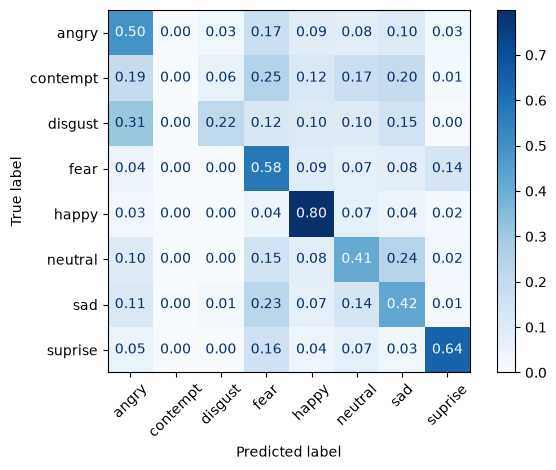

In [6]:
os.makedirs("train2", exist_ok=True)

EQUIV = {"surprise": "suprise"}
clases = sorted(
    d
    for d in os.listdir("dataset/validation")
    if os.path.isdir(os.path.join("dataset/validation", d))
)
rutas, y_true = [], []
for i, c in enumerate(clases):
    d = os.path.join("dataset/validation", c)
    for f in os.listdir(d):
        if f.lower().endswith(EXTENSIONES):
            rutas.append(os.path.join(d, f))
            y_true.append(i)

y_pred = []
for r in rutas:
    res = DeepFace.analyze(
        cv2.imread(r),
        actions=["emotion"],
        detector_backend="skip",
        enforce_detection=False,
        silent=True,
    )[0]
    e = res["dominant_emotion"]
    y_pred.append(clases.index(EQUIV.get(e, e)))

print(classification_report(y_true, y_pred, target_names=clases, zero_division=0))
print("F1 marcro:", f1_score(y_true, y_pred, average="macro"))

ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=clases, normalize="true", xticks_rotation=45, cmap="Blues", values_format=".2f")
plt.tight_layout()
plt.savefig("./train2/matriz_confusion_deepface.png", dpi=150)
plt.show()